**Import Libraries**

In [4]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

**Task 1: Load dataset and Check for Missing values**

In [5]:
# Load dataset
df = pd.read_csv("loan_data.csv")

# Check number of missing values per column
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,1
loan_amnt,1
loan_intent,1
loan_int_rate,1
loan_percent_income,1


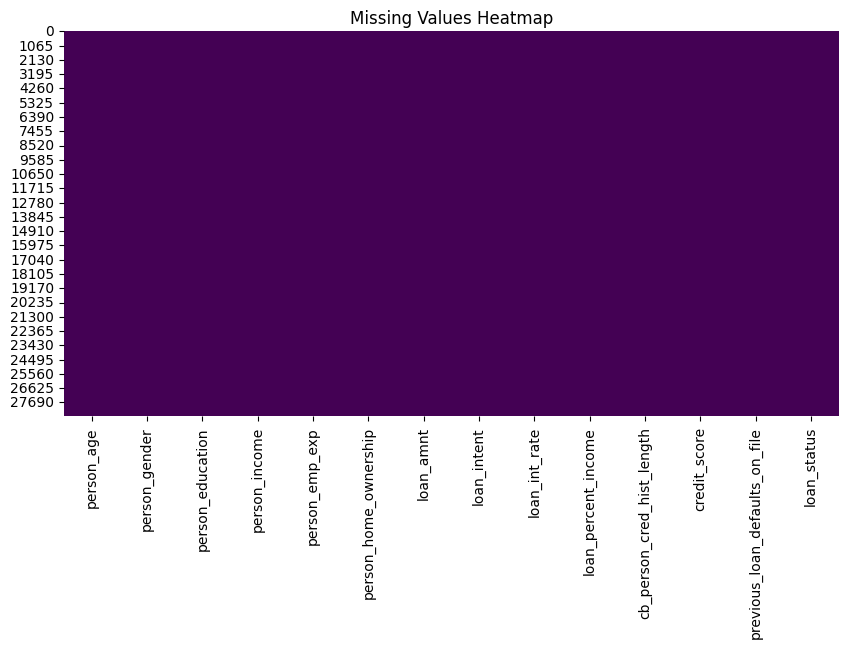

In [6]:
# heatmap to Visualize missing values
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

**Task 2: Outlier Detection & Removal**

* We focused on person_income because it has the largest range and potential extreme values, which can skew the model.

* loan_amnt and loan_int_rate may be large ranges, but extreme values are rarer or already cut off by the bank’s rules.

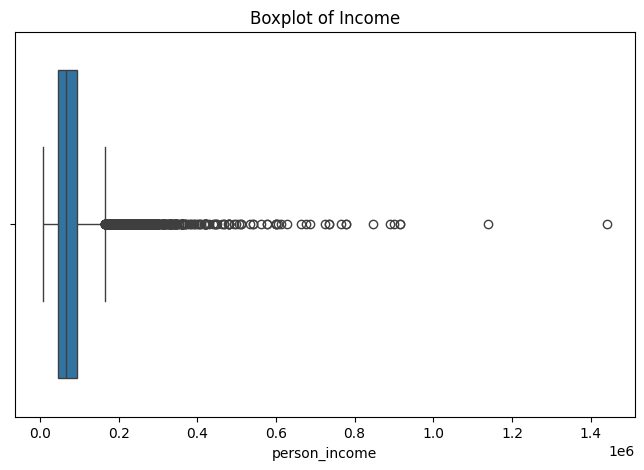

In [7]:
# 1. Visualize outliers with boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x=df['person_income'])
plt.title("Boxplot of Income")
plt.show()

In [8]:
# 2. Use IQR method to detect outliers in person_income
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -24851.375
Upper Bound: 166493.625


In [9]:
# 3. Remove outliers
df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()

In [10]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (28736, 14)
After outlier removal: (27414, 14)


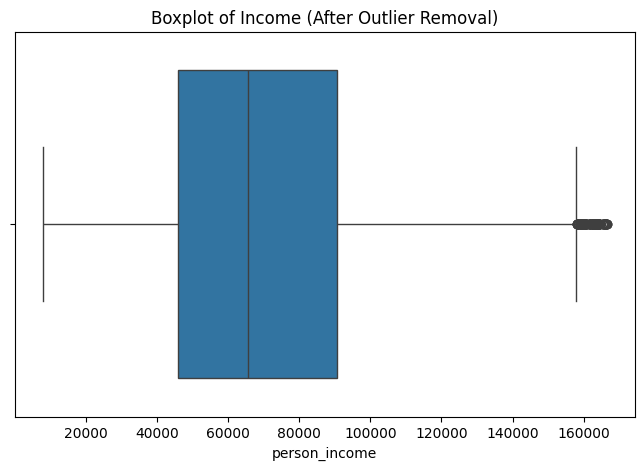

In [11]:
# After removing outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['person_income'])
plt.title("Boxplot of Income (After Outlier Removal)")
plt.show()

**Task 3: Encoding Categorical Variables**

In [12]:
# Identify categorical columns
cat_cols = df_clean.select_dtypes(include='object').columns
print("Categorical Columns:", cat_cols.tolist())

Categorical Columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


* Label encoding is applied to peron_gender and previous_loan_defaults_on_file due to them being binary categories which means they only have two outputs.

In [13]:
# Label Encode binary categories
le = LabelEncoder()
df_clean['person_gender'] = le.fit_transform(df_clean['person_gender'])  # male/female
df_clean['previous_loan_defaults_on_file'] = le.fit_transform(df_clean['previous_loan_defaults_on_file'])  # yes/no

* One-hot encoding applied to person_education, person_home_ownership, loan_intent due to them having multiple outputs.

In [14]:
# One-Hot Encode multi-class categorical variables
df_clean = pd.get_dummies(df_clean,
                           columns=['person_education','person_home_ownership','loan_intent'],
                           drop_first=True)

In [15]:
# Display first five rows to check encoding
df_clean.head()

,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22,0,71948,0,35000.0,16.02,0.49,3.0,561.0,0,...,False,True,False,False,True,False,False,False,True,False
1,21,0,12282,0,1000.0,11.14,0.08,2.0,504.0,1,...,True,False,False,True,False,True,False,False,False,False
2,25,0,12438,3,5500.0,12.87,0.44,3.0,635.0,0,...,True,False,False,False,False,False,False,True,False,False
3,23,0,79753,0,35000.0,15.23,0.44,2.0,675.0,0,...,False,False,False,False,True,False,False,True,False,False
4,24,1,66135,1,35000.0,14.27,0.53,4.0,586.0,0,...,False,True,False,False,True,False,False,True,False,False


**Task 4: Feature Scaling**

In [16]:
# Numeric columns
num_cols = ['person_age','person_income','person_emp_exp',
            'loan_amnt','loan_int_rate','loan_percent_income',
            'cb_person_cred_hist_length','credit_score']

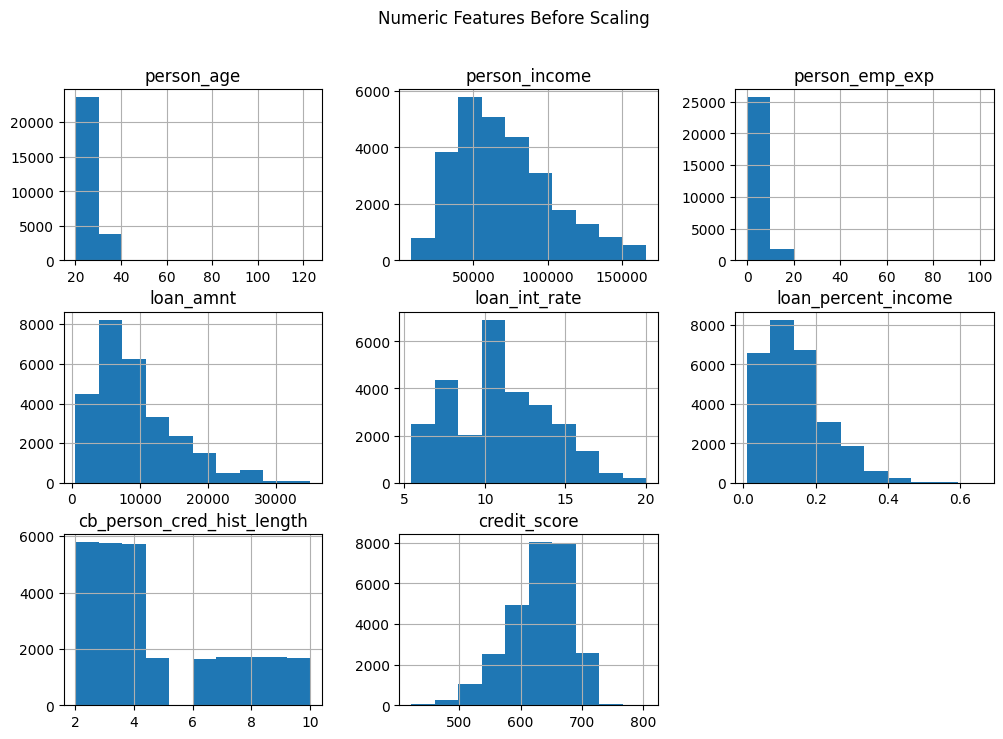

In [17]:
# Histograms before scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features Before Scaling")
plt.show()



* StandardScaling ensures that all features are scaled to equal ranges. It centers the data around 0 and scales by standard deviation, preserving the feature's distribution.



In [18]:
# Apply StandardScaler
scaler = StandardScaler()
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])

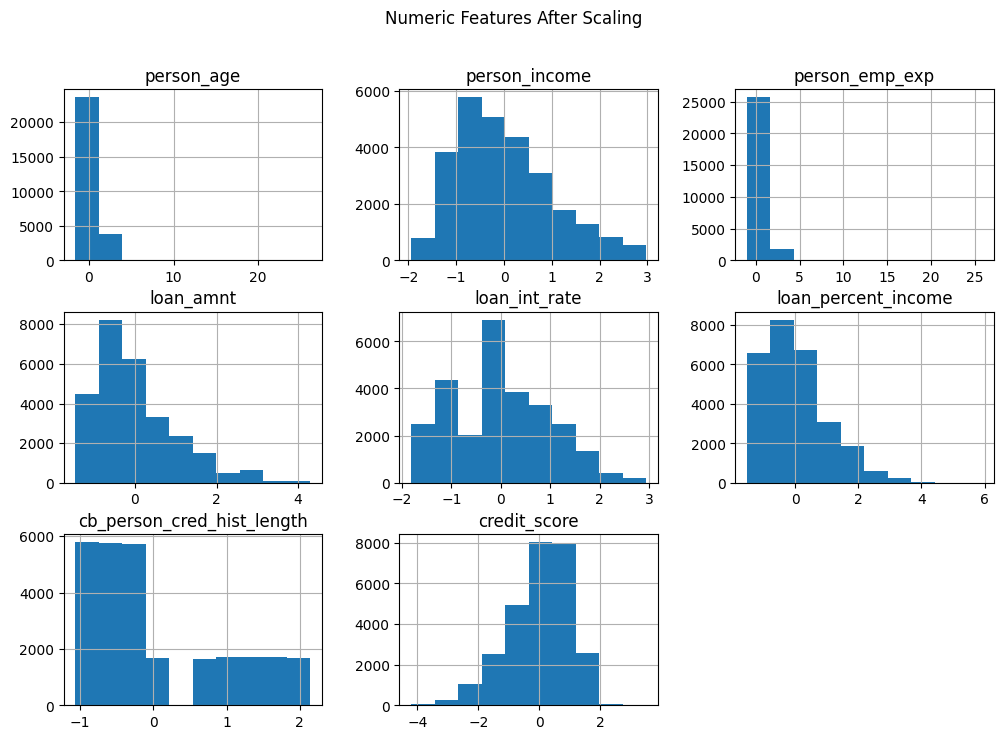

In [19]:
# Histograms after scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features After Scaling")
plt.show()

Task 5: Feature Engineering & EDA



* Debt-to income ratio measures the proportion of income used for the loan. It will help identify applicants with higher financial risk which will be valuable for predicting loan status.



In [20]:
# Debt-to-Income Ratio
df_clean['debt_to_income_ratio'] = df_clean['loan_amnt'] / df_clean['person_income']



* Age is divided into four categories (Young, Adult, Senior, Elder) for futher clarity. Then they are encoded using one-hot encoding.



In [21]:
# Age groups
bins = [18, 30, 50, 65, 100]
labels = ['Young','Adult','Senior','Elder']
df_clean['age_group'] = pd.cut(df_clean['person_age'], bins=bins, labels=labels)

In [22]:
# One-Hot Encode age_group
df_clean = pd.get_dummies(df_clean, columns=['age_group'], drop_first=True)



* A correlation heatmap is plotted to examin relationship between numeric features.


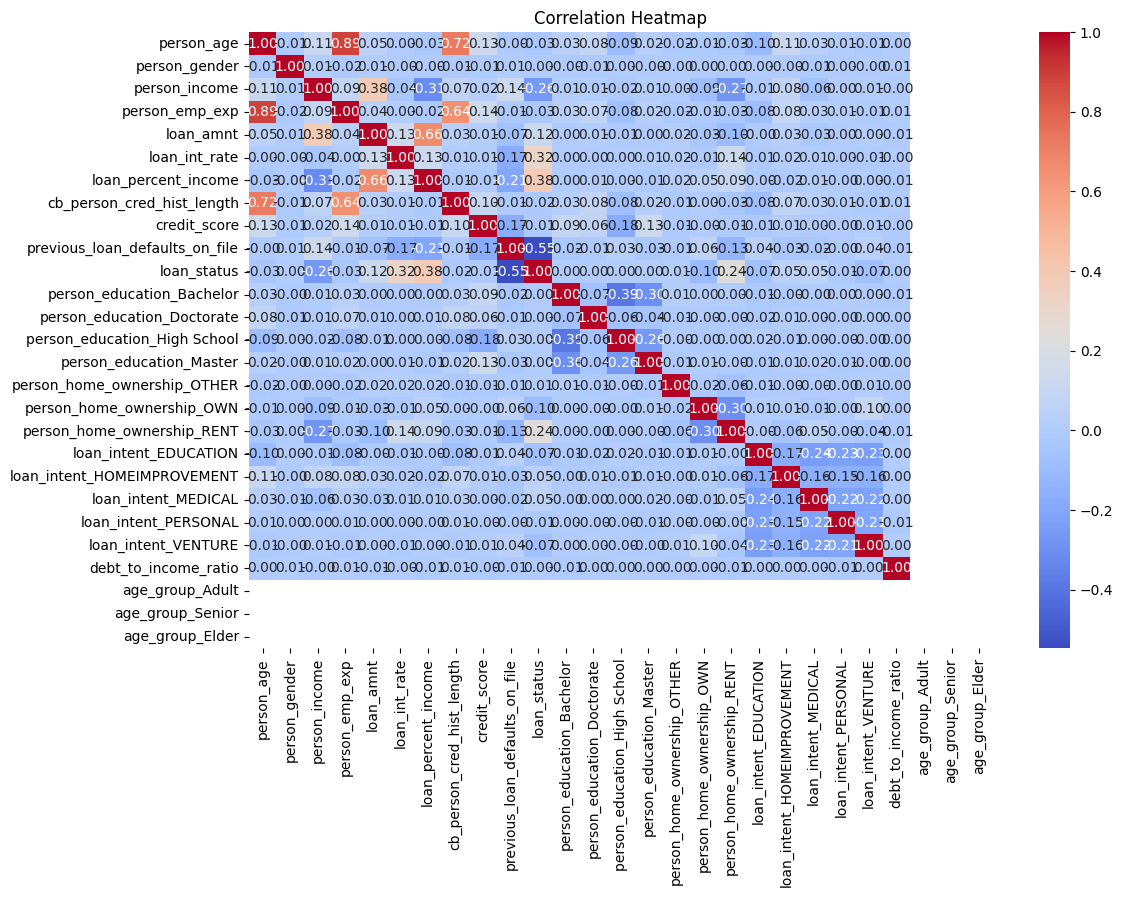

In [23]:
# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()



* We used a countplot to show how many applicants defaulted and how many did not.








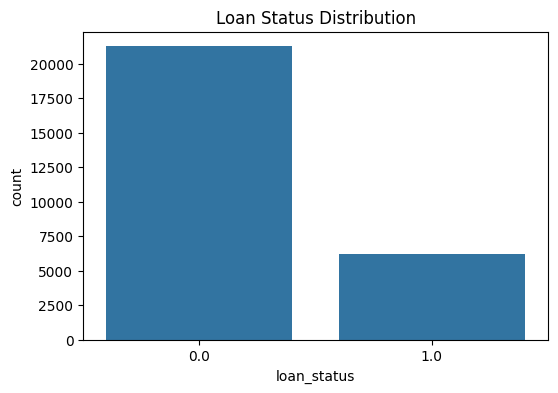

In [24]:
# Class balance
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df_clean)
plt.title("Loan Status Distribution")
plt.show()

* We used a boxplot to quickly see if people who failed to pay back their loans (Defult) typically had more debt than people who paid them back (No defult).

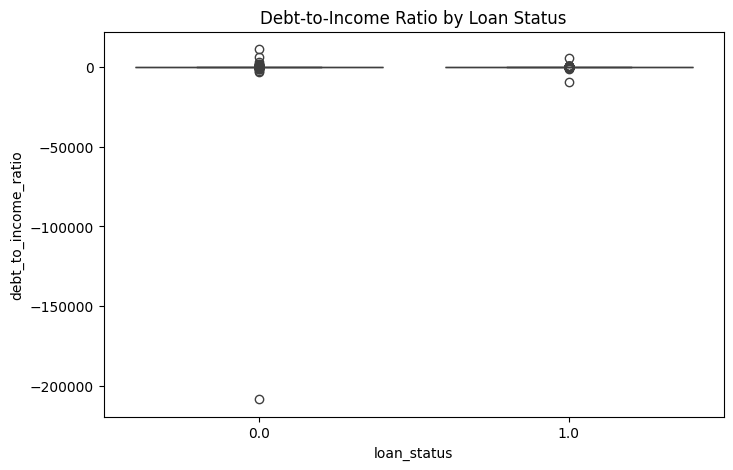

In [25]:
# Debt-to-Income vs Loan Status
plt.figure(figsize=(8,5))
sns.boxplot(x='loan_status', y='debt_to_income_ratio', data=df_clean)
plt.title("Debt-to-Income Ratio by Loan Status")
plt.show()

**Task 6: Feature Selection**

In [26]:
# Correlation with target variable
corr_target = df_clean.corr()['loan_status'].sort_values(ascending=False)
print("Correlation with loan_status:\n", corr_target)

Correlation with loan_status:
 loan_status                       1.000000
loan_percent_income               0.384123
loan_int_rate                     0.315187
person_home_ownership_RENT        0.237000
loan_amnt                         0.121066
loan_intent_MEDICAL               0.053274
loan_intent_HOMEIMPROVEMENT       0.047642
person_home_ownership_OTHER       0.013386
person_education_High School      0.004484
person_education_Master           0.004200
debt_to_income_ratio              0.002456
person_education_Bachelor         0.002443
person_gender                     0.002295
person_education_Doctorate        0.001749
credit_score                     -0.011724
loan_intent_PERSONAL             -0.014260
cb_person_cred_hist_length       -0.020950
person_emp_exp                   -0.027036
person_age                       -0.031294
loan_intent_EDUCATION            -0.065676
loan_intent_VENTURE              -0.073861
person_home_ownership_OWN        -0.102771
person_income          



* We used a barplot to visualize the feature importance base on correolation.




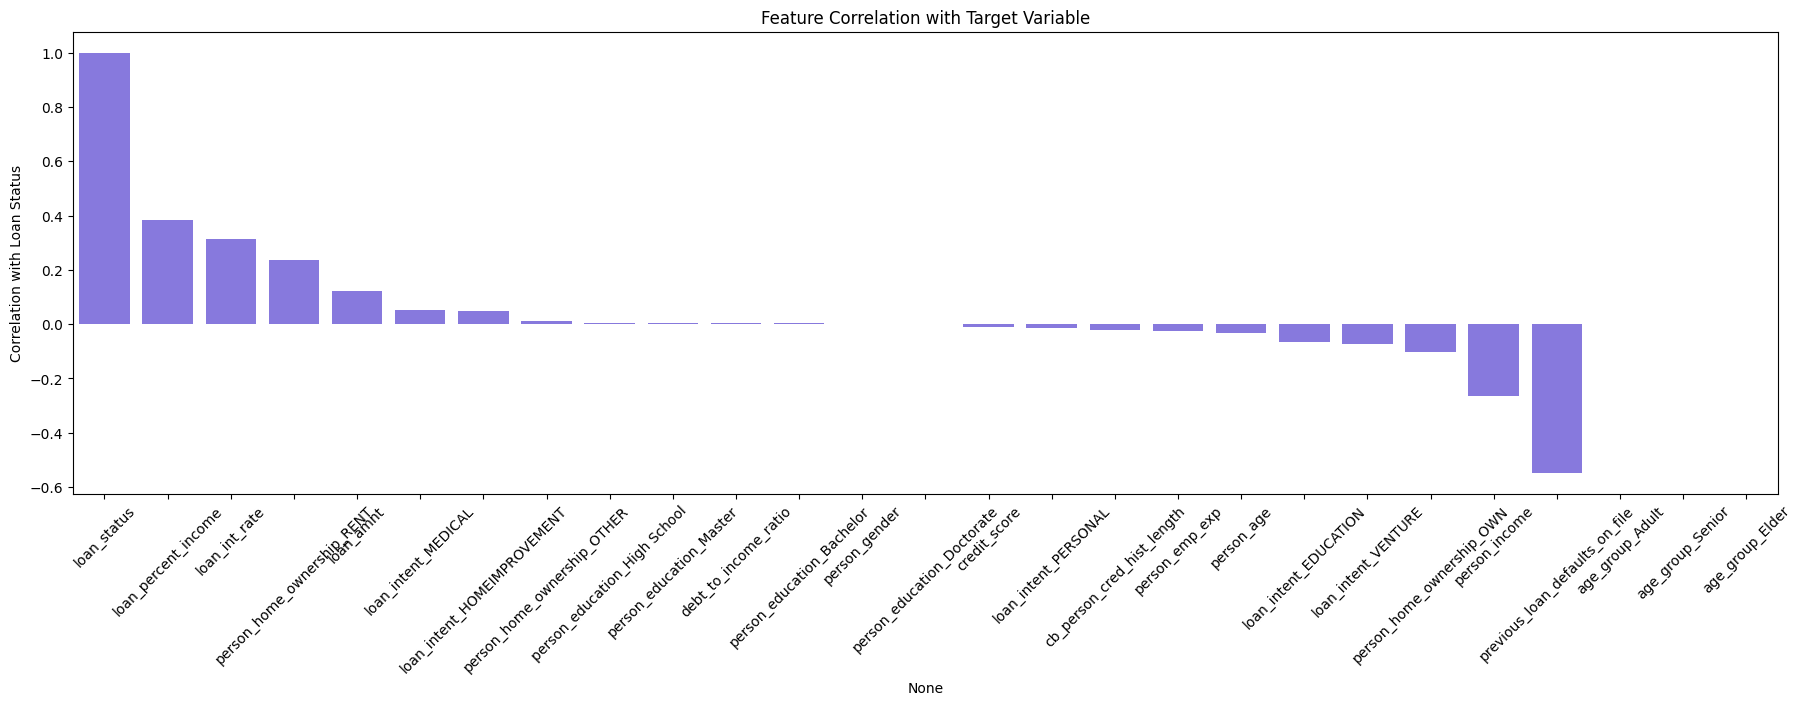

In [27]:
# Bar plot
plt.figure(figsize=(22,6))
sns.barplot(
    x=corr_target.index,
    y=corr_target.values,
    color="mediumslateblue"
)
plt.xticks(rotation=45)
plt.ylabel("Correlation with Loan Status")
plt.title("Feature Correlation with Target Variable")
plt.show()

In [28]:
df_final = df_clean.copy()

print("----- First 5 rows of final dataset -----")
display(df_final.head())

----- First 5 rows of final dataset -----


,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,debt_to_income_ratio,age_group_Adult,age_group_Senior,age_group_Elder
0,-1.064527,0,0.039396,-1.003595,4.294687,1.642728,3.967939,-0.666338,-1.394783,0,...,True,False,False,False,True,False,109.014316,False,False,False
1,-1.334026,0,-1.810252,-1.003595,-1.374303,0.051769,-0.723836,-1.067493,-2.537764,1,...,False,True,False,False,False,False,0.759178,False,False,False
2,-0.256031,0,-1.805416,-0.207145,-0.623996,0.615777,3.395771,-0.666338,0.089086,0,...,False,False,False,True,False,False,0.345624,False,False,False
3,-0.795028,0,0.281351,-1.003595,4.294687,1.385175,3.395771,-1.067493,0.891178,0,...,True,False,False,True,False,False,15.264525,False,False,False
4,-0.525529,1,-0.140808,-0.738112,4.294687,1.072200,4.425673,-0.265183,-0.893476,0,...,True,False,False,True,False,False,-30.500405,False,False,False


In [29]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

* We used a barplot to visualize the feature importance base on Mutual information and selectKBest.


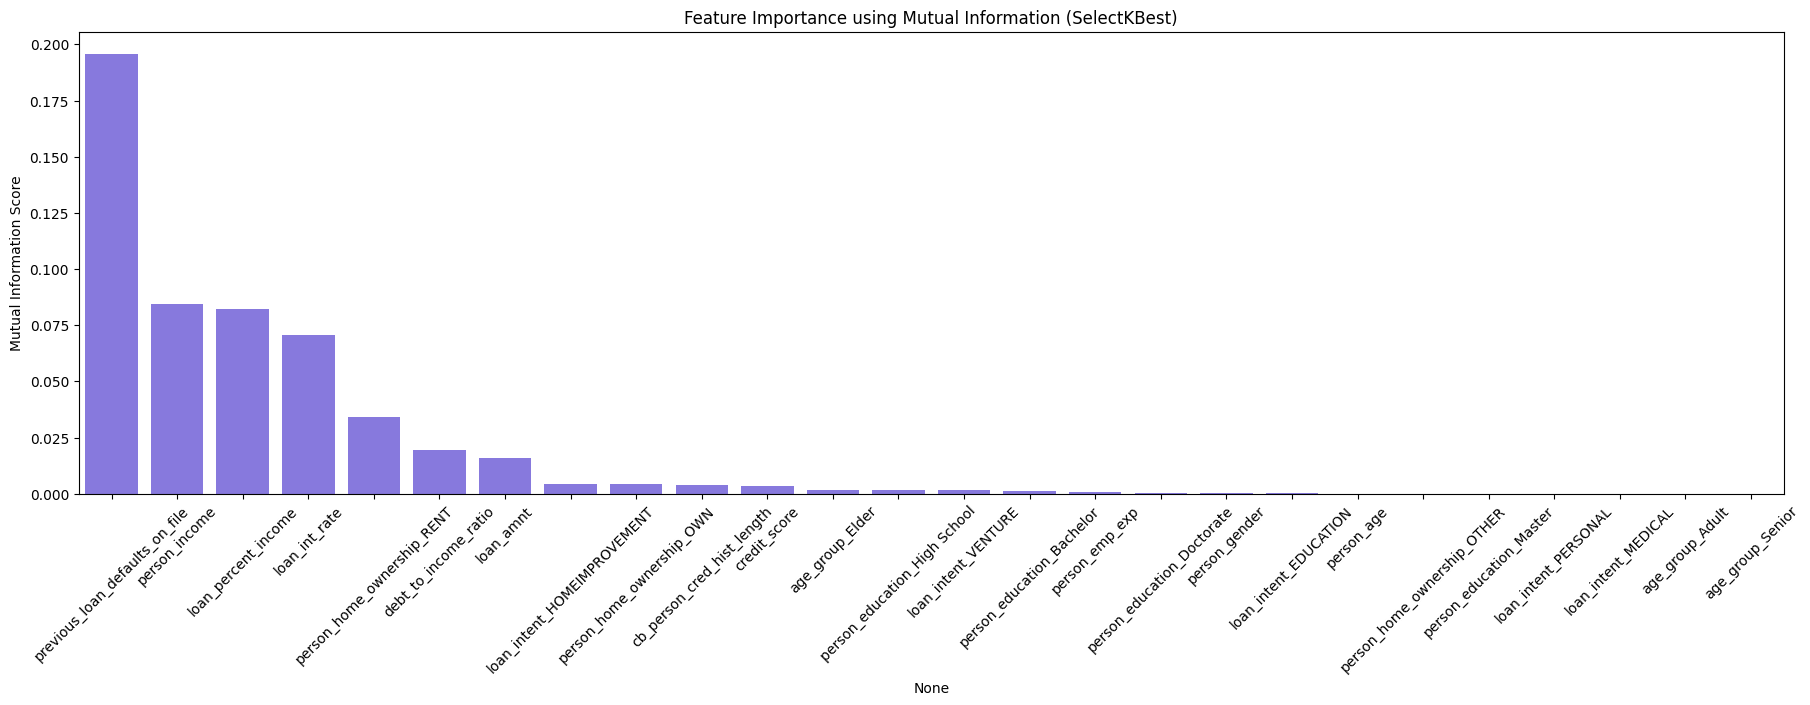

In [30]:
X = df_final.drop('loan_status', axis=1)
y = df_final['loan_status']

# SelectKBest with Mutual Information
kbest_selector = SelectKBest(score_func=mutual_info_classif, k='all')
kbest_selector.fit(X, y)
kbest_scores = pd.Series(kbest_selector.scores_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(22,6))
sns.barplot(x=kbest_scores.index, y=kbest_scores.values, color="mediumslateblue")
plt.xticks(rotation=45)
plt.ylabel("Mutual Information Score")
plt.title("Feature Importance using Mutual Information (SelectKBest)")
plt.show()

* We used a barplot to visualize the feature importance base on Random forest.


Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_HOMEIMPROVEMENT', 'debt_to_income_ratio'],
      dtype='object')


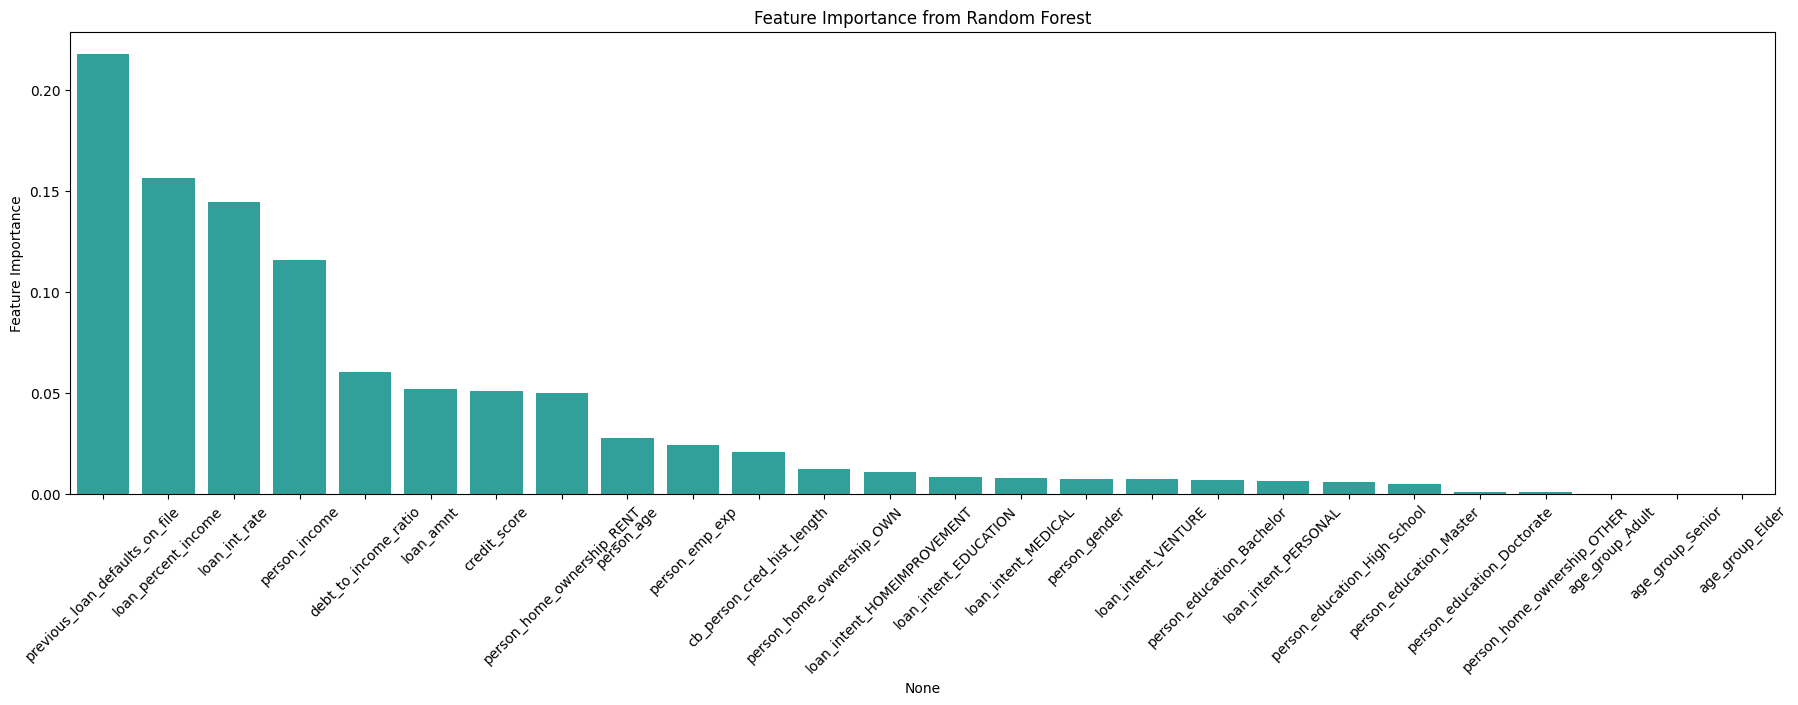

In [31]:
# Model-Based Feature Selection with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(22,6))
sns.barplot(x=importances.index, y=importances.values, color="lightseagreen")
plt.xticks(rotation=45)
plt.ylabel("Feature Importance")
plt.title("Feature Importance from Random Forest")
plt.show()

* we picked Variance threshold and random forest as
our methods for feature selection



**Select methos 1: Variance threshold **

In [32]:
# Drop low varaince features with varince threshold
from sklearn.feature_selection import VarianceThreshold

# Apply Variance Threshold
var_thresh = VarianceThreshold(threshold=0.01)  # threshold=0 means drop only constant cols
X_var = var_thresh.fit_transform(X)
kept_after_var = X.columns[var_thresh.get_support()]

print("Features kept after Variance Threshold:", kept_after_var.tolist())

# Identify dropped ones
dropped_by_var = [col for col in X.columns if col not in kept_after_var]
print("Features dropped by Variance Threshold:", dropped_by_var)

Features kept after Variance Threshold: ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_education_Bachelor', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio']
Features dropped by Variance Threshold: ['person_education_Doctorate', 'person_home_ownership_OTHER', 'age_group_Adult', 'age_group_Senior', 'age_group_Elder']


In [33]:
print("Original shape:", df_final.shape)
print(df_final.head())

Original shape: (27414, 27)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -1.064527              0       0.039396       -1.003595   4.294687   
1   -1.334026              0      -1.810252       -1.003595  -1.374303   
2   -0.256031              0      -1.805416       -0.207145  -0.623996   
3   -0.795028              0       0.281351       -1.003595   4.294687   
4   -0.525529              1      -0.140808       -0.738112   4.294687   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.642728             3.967939                   -0.666338   
1       0.051769            -0.723836                   -1.067493   
2       0.615777             3.395771                   -0.666338   
3       1.385175             3.395771                   -1.067493   
4       1.072200             4.425673                   -0.265183   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.394783                               0  ...   


In [34]:
# After dropping low variance features
X_var_df = pd.DataFrame(X_var, columns=kept_after_var)
print("Shape after VarianceThreshold:", X_var_df.shape)
print(X_var_df.head())

Shape after VarianceThreshold: (27414, 21)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -1.064527            0.0       0.039396       -1.003595   4.294687   
1   -1.334026            0.0      -1.810252       -1.003595  -1.374303   
2   -0.256031            0.0      -1.805416       -0.207145  -0.623996   
3   -0.795028            0.0       0.281351       -1.003595   4.294687   
4   -0.525529            1.0      -0.140808       -0.738112   4.294687   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.642728             3.967939                   -0.666338   
1       0.051769            -0.723836                   -1.067493   
2       0.615777             3.395771                   -0.666338   
3       1.385175             3.395771                   -1.067493   
4       1.072200             4.425673                   -0.265183   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.394783                          

In [35]:
df = X_var_df.copy()

In [36]:
print("New shape:", df.shape)
print(df.head())

New shape: (27414, 21)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -1.064527            0.0       0.039396       -1.003595   4.294687   
1   -1.334026            0.0      -1.810252       -1.003595  -1.374303   
2   -0.256031            0.0      -1.805416       -0.207145  -0.623996   
3   -0.795028            0.0       0.281351       -1.003595   4.294687   
4   -0.525529            1.0      -0.140808       -0.738112   4.294687   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.642728             3.967939                   -0.666338   
1       0.051769            -0.723836                   -1.067493   
2       0.615777             3.395771                   -0.666338   
3       1.385175             3.395771                   -1.067493   
4       1.072200             4.425673                   -0.265183   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.394783                             0.0  ...   
1    

In [37]:
print(df.dtypes)

person_age                        float64
person_gender                     float64
person_income                     float64
person_emp_exp                    float64
loan_amnt                         float64
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                      float64
previous_loan_defaults_on_file    float64
person_education_Bachelor         float64
person_education_High School      float64
person_education_Master           float64
person_home_ownership_OWN         float64
person_home_ownership_RENT        float64
loan_intent_EDUCATION             float64
loan_intent_HOMEIMPROVEMENT       float64
loan_intent_MEDICAL               float64
loan_intent_PERSONAL              float64
loan_intent_VENTURE               float64
debt_to_income_ratio              float64
dtype: object


**Select method 2: Random Forest**

In [38]:
# Train Random Forest on variance-thresholded features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(df, y)

# Select features above median importance
model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = df.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


In [39]:
# Create dataset with only selected features
X_final = df[selected_features]

**Final output after feature selection**

In [40]:
print("New shape:", X_final.shape)
print(X_final.head())

New shape: (27414, 11)
   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0   -1.064527       0.039396       -1.003595   4.294687       1.642728   
1   -1.334026      -1.810252       -1.003595  -1.374303       0.051769   
2   -0.256031      -1.805416       -0.207145  -0.623996       0.615777   
3   -0.795028       0.281351       -1.003595   4.294687       1.385175   
4   -0.525529      -0.140808       -0.738112   4.294687       1.072200   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0             3.967939                   -0.666338     -1.394783   
1            -0.723836                   -1.067493     -2.537764   
2             3.395771                   -0.666338      0.089086   
3             3.395771                   -1.067493      0.891178   
4             4.425673                   -0.265183     -0.893476   

   previous_loan_defaults_on_file  person_home_ownership_RENT  \
0                             0.0                         

In [46]:
X_final.to_csv(r'C:\Users\User\Downloads\result.csv', index=False)

In [48]:
# Create a new DataFrame with selected features and the target variable
df_final = X_final.copy()
df_final['loan_status'] = df_clean['loan_status']

df_final.to_csv(r'C:\Users\User\Downloads\result.csv', index=False)